
# Finding Structure in Data: Discovering Phases in the 2D Ising Model

## Can unsupervised machine learning discover ordered and disordered states in the 2D Ising model without knowing the temperatures?

The Ising model is a simple model of magnetism that exhibits a phase transition.

At low temperatures, spins tend to align, producing an ordered state.

At high temperatures, thermal fluctuations create disorder.

The goal of this project is to investigate whether PCA and K-Means clustering can identify these patterns directly from spin configurations.

## Methods
- Monte Carlo simulation using the Metropolis algorithm
- Principal Component Analysis (PCA)
- K-Means clustering
- Comparison with physical magnetization


In [1]:

%pip install numpy matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

np.random.seed(42)



## 1. Simulating the 2D Ising Model

We simulate a 2D square lattice where each spin can be either +1 or -1.

The energy of the system is

$$
H = -J \sum_{\langle i,j \rangle} s_i s_j
$$

where J is the interaction strength and s represents a spin.

We use the Metropolis algorithm to generate spin configurations at different temperatures.

Periodic boundary conditions are applied to avoid boundary effects.

For simplicity, we set J = 1 and k_B = 1.


In [3]:

L = 12

def ising_simulation(T, steps=200):
    spins = np.random.choice([-1, 1], size=(L, L))

    for step in range(steps * L * L):
        i = np.random.randint(L)
        j = np.random.randint(L)

        neighbors = (
            spins[(i+1)%L, j] +
            spins[(i-1)%L, j] +
            spins[i, (j+1)%L] +
            spins[i, (j-1)%L]
        )

        dE = 2 * spins[i, j] * neighbors

        if dE <= 0 or np.random.rand() < np.exp(-dE/T):
            spins[i, j] *= -1

    return spins



## 2. Generating the Dataset

We generate spin configurations at six different temperatures:

T = 1.0, 1.5, 2.0, 2.3, 3.0, and 4.0.

For each temperature, we generate 20 configurations.

Each 12 x 12 configuration is flattened into a vector of 144 spin values.

The final dataset contains 120 samples and 144 features.

The temperatures are saved separately for visualization and analysis. They are not used as input features for PCA or K-Means.


In [4]:

temperatures = [1.0, 1.5, 2.0, 2.3, 3.0, 4.0]

data = []
labels = []

for T in temperatures:
    for n in range(20):
        spins = ising_simulation(T)
        data.append(spins.flatten())
        labels.append(T)

data = np.array(data)
labels = np.array(labels)

print("Dataset shape:", data.shape)


Dataset shape: (120, 144)



## 3. Visualizing Spin Configurations

We visualize spin configurations at three temperatures to understand how the system changes.

- T = 1.0: We expect an ordered configuration with mostly aligned spins.
- T = 2.3: The system is close to the critical temperature, where fluctuations become important.
- T = 4.0: We expect a more disordered configuration.

The exact critical temperature of the infinite 2D Ising model is approximately T_c = 2.269.

This visualization helps us understand the physical patterns before applying machine learning.


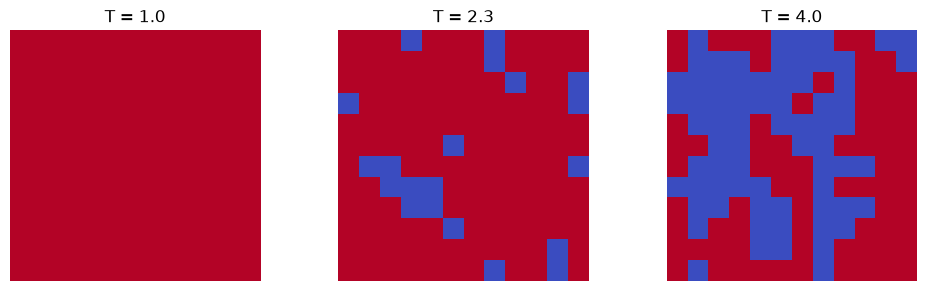

In [5]:

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for ax, T in zip(axes, [1.0, 2.3, 4.0]):
    spins = ising_simulation(T)
    ax.imshow(spins, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(f"T = {T}")
    ax.axis("off")

plt.tight_layout()
plt.show()


The spin configurations show how temperature affects the Ising model.

- **T = 1.0:** Almost all spins are aligned, showing a strongly ordered magnetic state.
- **T = 2.3:** Most spins are still aligned, but small regions of opposite spins appear. The system is close to the critical temperature.
- **T = 4.0:** The spins are much more disordered, with larger regions of opposite orientations.

These results show the transition from ordered to disordered magnetic behavior as temperature increases.

This motivates our next step: using machine learning to detect these patterns automatically.



## 4. Principal Component Analysis (PCA)

Each spin configuration contains 144 features, making direct visualization difficult.

We use PCA to reduce the data from 144 dimensions to 2 dimensions.

PCA identifies directions of maximum variance in the dataset.

Our goal is to investigate whether configurations with different magnetic behavior form recognizable patterns in the PCA space.

The algorithm does not know the temperature labels during training.


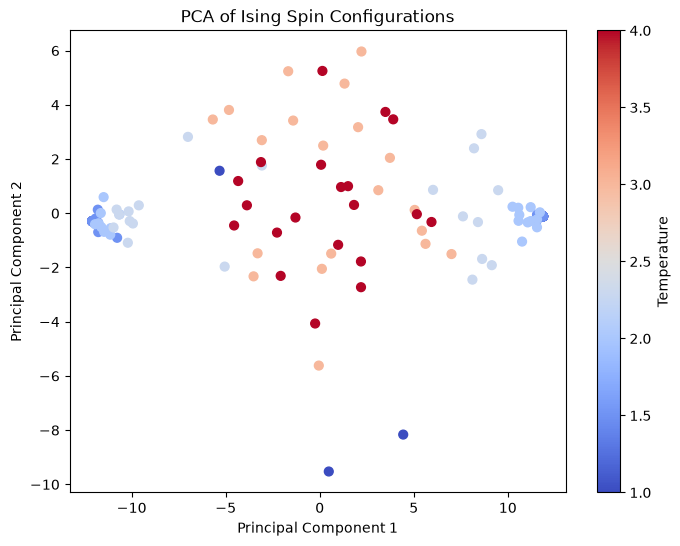

Explained variance: [0.56905428 0.02978079]


In [6]:

pca = PCA(n_components=2)

X_pca = pca.fit_transform(data)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="coolwarm",
    s=40
)

plt.colorbar(label="Temperature")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Ising Spin Configurations")

plt.show()

print("Explained variance:", pca.explained_variance_ratio_)


PCA revealed a clear structure in the spin configurations.

The first principal component (PC1) explains approximately 56.91% of the total variance, while PC2 explains about 2.98%.

Low-temperature configurations are mostly concentrated in two groups on opposite sides of the PC1 axis.

High-temperature configurations are more scattered around the center.

This suggests that PCA has identified a feature related to magnetic ordering.

Importantly, PCA discovered this structure without using temperature labels during training.

The next step is to test whether PC1 is related to magnetization.



## 5. K-Means Clustering

Next, we apply K-Means clustering to the PCA-transformed data.

K-Means groups similar configurations based on their positions in the reduced feature space.

We choose three clusters to explore whether the data separates into positive magnetization, negative magnetization, and near-zero magnetization regions.

These clusters should not automatically be interpreted as three distinct thermodynamic phases.

We compare the clusters with temperature to understand their physical meaning.


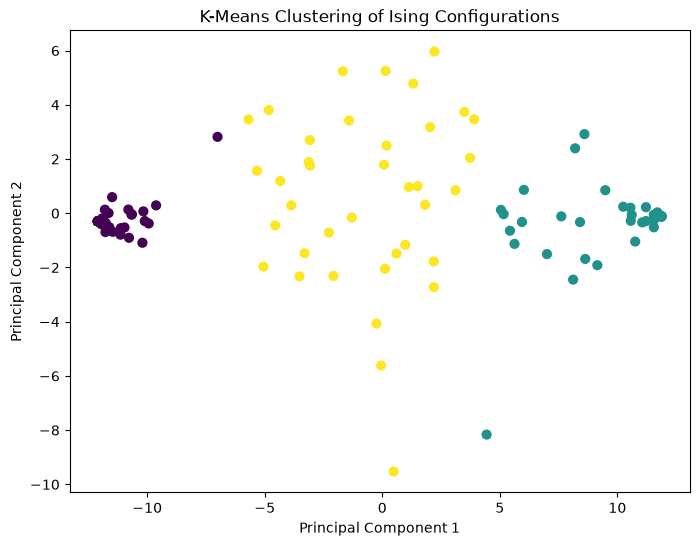

In [7]:

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_pca)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Ising Configurations")

plt.show()



K-Means successfully divided the PCA data into three clusters.

- **Left cluster (purple):** Contains configurations with strongly negative PC1 values.
- **Right cluster (green):** Contains configurations with strongly positive PC1 values.
- **Middle cluster (yellow):** Contains configurations with intermediate PC1 values and a wider spread along PC2.

Comparing this plot with the temperature-colored PCA visualization, the left and right clusters mainly contain low-temperature configurations.

The middle cluster contains many high-temperature configurations.

This suggests that the clustering algorithm can distinguish different magnetic ordering patterns without temperature labels.

However, these three clusters do not necessarily represent three different physical phases.



## 6. Connecting PCA to Physics

To understand what PCA has discovered, we compare the first principal component with magnetization.

Magnetization is defined as

$$
M = \frac{1}{N}\sum_{i=1}^{N}s_i
$$

where N is the total number of spins.

Magnetization is an order parameter for the Ising model.

If PC1 strongly correlates with magnetization, this suggests that PCA has identified a physically meaningful feature of the system.

We calculate the Pearson correlation coefficient to quantify this relationship.


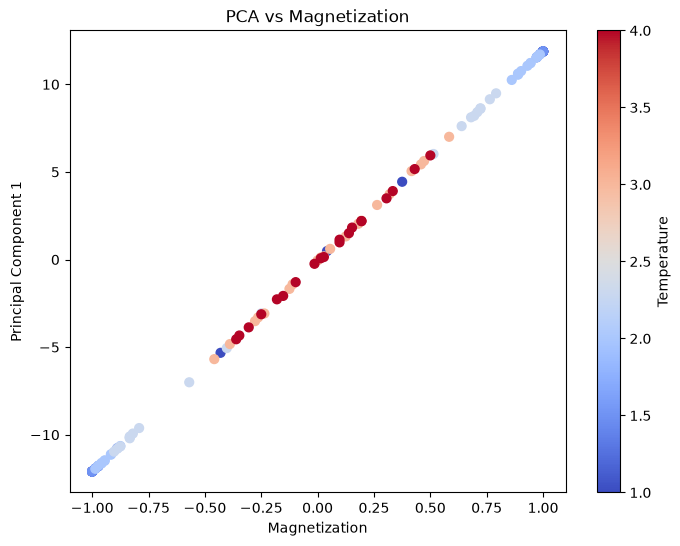

Correlation: 0.9999855360109697


In [8]:

magnetization = np.mean(data, axis=1)

plt.figure(figsize=(8, 6))

plt.scatter(
    magnetization,
    X_pca[:, 0],
    c=labels,
    cmap="coolwarm",
    s=40
)

plt.xlabel("Magnetization")
plt.ylabel("Principal Component 1")
plt.title("PCA vs Magnetization")
plt.colorbar(label="Temperature")

plt.show()

correlation = np.corrcoef(
    magnetization, X_pca[:, 0]
)[0, 1]

print("Correlation:", correlation)


The results show an extremely strong linear relationship between the first principal component (PC1) and magnetization.

The Pearson correlation coefficient is:

**r = 0.9999855**

This value is very close to 1, indicating an almost perfect positive correlation.

- When magnetization is close to +1, PC1 is strongly positive.
- When magnetization is close to -1, PC1 is strongly negative.
- When magnetization is close to 0, PC1 is also close to 0.

This is the most important result of our project.

PCA was not explicitly given magnetization or temperature as input. It only analyzed the raw spin configurations.

However, the first principal component is almost perfectly correlated with magnetization, which is the order parameter of the Ising model.

**Conclusion:** PCA successfully identified a physically meaningful structure in the data without supervised learning.



## 7. Magnetization vs Temperature

For each spin configuration, we calculate the absolute magnetization:

$$
|M| = \left|\frac{1}{N}\sum_{i=1}^{N}s_i\right|
$$

We use absolute magnetization because the system can have either positive or negative magnetization in the ordered phase.

We then calculate the average absolute magnetization at each temperature.

### Expected Behavior

- At low temperatures, |M| should be close to 1, indicating strong magnetic order.
- Near the critical temperature (T_c ≈ 2.269), magnetic fluctuations become important.
- At high temperatures, average |M| should decrease as the spins become more disordered.


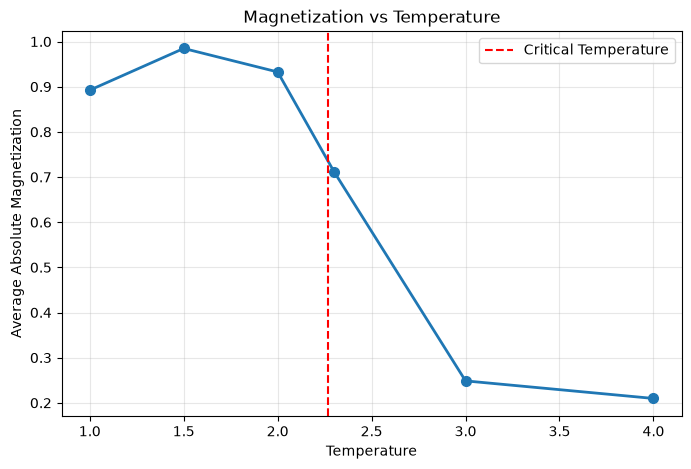

T = 1.0, Average |M| = 0.892
T = 1.5, Average |M| = 0.985
T = 2.0, Average |M| = 0.933
T = 2.3, Average |M| = 0.712
T = 3.0, Average |M| = 0.249
T = 4.0, Average |M| = 0.210


In [9]:

# Calculate magnetization
magnetization = np.mean(data, axis=1)

# Calculate average absolute magnetization
avg_magnetization = []

for T in temperatures:
    values = np.abs(magnetization[labels == T])
    avg_magnetization.append(np.mean(values))

# Plot
plt.figure(figsize=(8, 5))

plt.plot(
    temperatures,
    avg_magnetization,
    "o-",
    linewidth=2,
    markersize=7
)

plt.axvline(
    x=2.269,
    color="red",
    linestyle="--",
    label="Critical Temperature"
)

plt.xlabel("Temperature")
plt.ylabel("Average Absolute Magnetization")
plt.title("Magnetization vs Temperature")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Print numerical results
for T, M in zip(temperatures, avg_magnetization):
    print(f"T = {T:.1f}, Average |M| = {M:.3f}")



The results show how magnetic ordering changes with temperature.

At low temperatures, the system is strongly ordered:

- T = 1.0: Average |M| = 0.892
- T = 1.5: Average |M| = 0.985
- T = 2.0: Average |M| = 0.933

Near the theoretical critical temperature (T_c ≈ 2.269), magnetization decreases:

- T = 2.3: Average |M| = 0.712

At higher temperatures, magnetization becomes much smaller:

- T = 3.0: Average |M| = 0.249
- T = 4.0: Average |M| = 0.210

This behavior is consistent with the expected change from an ordered to a disordered magnetic state.

The lower magnetization at T = 1.0 compared with T = 1.5 may be caused by incomplete equilibration or statistical fluctuations.

The red dashed line represents the theoretical critical temperature of the infinite 2D Ising model, not a critical temperature independently measured by our simulation.

### Connection to PCA

Previously, PCA identified a strong relationship between PC1 and magnetization (r = 0.9999855).

The temperature dependence of magnetization helps explain why low-temperature configurations formed two groups in PCA space, while high-temperature configurations were concentrated closer to the center.

Together, these results demonstrate that unsupervised learning can reveal physically meaningful patterns in the Ising model.




## Final Conclusion

### Research Question
Can unsupervised machine learning discover ordered and disordered states in the 2D Ising model without knowing the temperatures?

### Main Findings

1. **Spin Configurations:** The system changes from strongly ordered configurations at low temperatures to more disordered configurations at high temperatures.

2. **PCA:** The first principal component explains 56.91% of the variance, revealing a dominant pattern in the spin configurations.

3. **K-Means Clustering:** Three clusters were identified in PCA space, corresponding to different magnetization regions.

4. **PCA and Magnetization:** The first principal component is almost perfectly correlated with magnetization (r = 0.9999855).

5. **Temperature Dependence:** Average absolute magnetization decreases substantially near and above the theoretical critical temperature.

### Physical Interpretation

PCA successfully recovered a feature closely related to the physical order parameter of the Ising model.

This is important because the algorithm was not explicitly given temperature or magnetization labels during training.
